# Replay vs. frozen alert archive


This notebook is a part of the alert-archive verification notebooks:
1. **Baseline vs. frozen:**
    - Just to make sure we're on track with the new alert-archive pipeline.
    - The baseline is a subset of the initial pq dump, so it is a subset of the frozen catalog.
2. **Replay vs frozen:** (⭐ you are here)
    - With the "daily replays" added to the baseline, this version of the **working catalog** now spans the entire original pq dump.
    - This means it can properly be compared to the **frozen catalog**, which was originally built by that same dump.
    - Spoiler alert, we find them to be equivalent :)
3. **Daily ingest summary:**
    - A summary of the working catalog after running the daily ingest process on the **new** alerts.
    - Because we are now going beyond the frozen catalog, this notebook instead explores the partitioning, coverage, etc.

> [!NOTE]
> This was run from a branch, against `olivia/daily-run @ a93c56c`

One-off comparison of the **working catalog** after the baseline and the full replay with the
**frozen** catalog that users and the nightly benchmarks use today. Written 2026-10-31.

How the working catalog was built:
- **Baseline** (Slurm job 42547515, `olivia/baseline` @ `db43161`): the dump's 263 Jun 26 chunks,
  10,772,712 alerts. Compared with the frozen catalog in `baseline_vs_frozen.ipynb`.
- **Replay** (`scripts/replay.sbatch` on `olivia/daily-run` @ `a93c56c`): the dump's remaining chunks,
  fed through the daily pipeline **one alertId prefix per run** (72 runs), as if they had arrived night by
  night. Each run checks the chunks' formats from their footers, imports them with hats-import into the
  existing pixels (`existing_pixels`, so pixels are never split), and writes one `<run_id>.parquet` per pixel.
  - A one-night trial (job 42567524), then several jobs: two were preempted (the `rubin:default` QOS on
    milano is preemptable) and resumed from where they stopped; the last was job 42574460.
  - Temporary: `landing/` isn't group-writable yet, so the replay copied chunks into, and the daily runs
    read from, `rubin_alert_archive_v2/replay_landing/`. So none of the converter's new chunks in
    `landing/` (171141, 171145, ...) are in this catalog yet.

| | Path |
|---|---|
| Working (new) | `/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive_v2/working` |
| Frozen | `/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive/rubin_alert_archive` |
| Input dump | `/sdf/data/rubin/user/ncaplar/alert-parquet` (6-digit prefix chunks only; the 5-digit ones are duplicates) |

Sections:
1. Was every input alert ingested exactly once?
2. The daily runs
3. Catalog properties side by side
4. Partitioning
5. Columns and schema
6. Which alerts differ between the two catalogs, and when they were observed
7. Spot check of values for alerts in both

In [1]:
from collections import Counter
from pathlib import Path

import hats
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from alert_archive.baseline import baseline_chunks
from alert_archive.config import PathConfig
from alert_archive.daily.increment import consolidated_file_name, leaf_files
from alert_archive.mock.replay import replay_nights
from alert_archive.state import PipelineState

paths = PathConfig()
WORKING = paths.working_dir
REPLAY_LANDING = paths.root / "replay_landing"  # temporary; see above
FROZEN = Path("/sdf/data/rubin/shared/lsdb_commissioning/rubin_alert_archive/rubin_alert_archive")
working, frozen = hats.read_hats(WORKING), hats.read_hats(FROZEN)
runs = PipelineState(paths.state_dir).runs()
baseline_run, replay_runs = runs[0], runs[1:]


def data_files(catalog_dir):
    """Every data parquet file of a catalog, for flat (Npix=N.parquet) or leaf-directory layouts."""
    dataset = Path(catalog_dir) / "dataset"
    return sorted(p for p in dataset.glob("Norder=*/Dir=*/**/*.parquet"))


def read_column(catalog_dir, column, files=None):
    """One column (dotted paths allowed for nested fields) from every file, as a flat arrow array."""
    field = column.partition(".")[2]
    chunks = []
    for path in files or data_files(catalog_dir):
        col = pq.read_table(path, columns=[column]).column(0).combine_chunks()
        if field and pa.types.is_struct(col.type):  # nested columns are struct-of-lists
            col = pc.struct_field(col, field)
        if pa.types.is_list(col.type) or pa.types.is_large_list(col.type):  # one diaSource per alert
            col = pc.list_flatten(col)
        chunks.append(col)
    return pa.concat_arrays(chunks)

## 1. Was every input alert ingested exactly once?

The input is every 6-digit-prefix chunk in the dump: the baseline's 263, plus the 72 replay nights'.
The chunks logged in `ingested.jsonl` should be exactly those, each once. Rows in the input chunks (from
their parquet footers), in the working catalog's files, logged in `ingested.jsonl` and in
`hats.properties` should all match.

In [2]:
input_chunks = baseline_chunks(paths.dump_dir) + [c for night in replay_nights(paths.dump_dir) for c in night]
logged = [c for r in runs for c in r.chunks]
input_rows = sum(pq.read_metadata(c).num_rows for c in input_chunks)
catalog_rows = sum(pq.read_metadata(p).num_rows for p in data_files(WORKING))

pd.DataFrame(
    {
        "count": [
            len(input_chunks),
            len(logged),
            len(set(logged)),
            input_rows,
            catalog_rows,
            sum(r.num_rows for r in runs),
            working.catalog_info.total_rows,
        ],
    },
    index=[
        "input chunks in the dump",
        "chunks logged in ingested.jsonl",
        "  of which unique",
        "rows in input chunks",
        "rows in working catalog files",
        "rows logged in ingested.jsonl",
        "hats_nrows in hats.properties",
    ],
).style.format("{:,}")

,count
input chunks in the dump,426
chunks logged in ingested.jsonl,426
of which unique,426
rows in input chunks,"16,466,969"
rows in working catalog files,"16,466,969"
rows logged in ingested.jsonl,"16,466,969"
hats_nrows in hats.properties,"16,466,969"


In [3]:
assert sorted(logged) == sorted(c.name for c in input_chunks)
assert input_rows == catalog_rows == sum(r.num_rows for r in runs) == working.catalog_info.total_rows
print("Chunks skipped by any run:", {k: v for r in runs for k, v in r.skipped.items()})
print("Format IDs:", sum((Counter(r.schema_id_counts) for r in runs), Counter()))

# The copies in replay_landing/ are byte-for-byte the same size as the dump's chunks.
replayed = [c for night in replay_nights(paths.dump_dir) for c in night]
print("Replay copies with the dump's size:",
      sum((REPLAY_LANDING / c.name).stat().st_size == c.stat().st_size for c in replayed), "of", len(replayed))

Chunks skipped by any run: {}
Format IDs: Counter({1100: 16466969})


Replay copies with the dump's size: 163 of 163


## 2. The daily runs

One row per replay run: the alertId prefix it replayed, how many chunks and alerts, and how long it took
(from its start to the next run's start, so it includes job restarts after preemption).

In [4]:
rdf = pd.DataFrame(
    {
        "run_id": [r.run_id for r in replay_runs],
        "prefix": [r.chunks[0].split("__")[0] for r in replay_runs],
        "chunks": [len(r.chunks) for r in replay_runs],
        "alerts": [r.num_rows for r in replay_runs],
        "started": pd.to_datetime([r.started for r in replay_runs]),
    }
)
assert (rdf["prefix"] == [r.chunks[-1].split("__")[0] for r in replay_runs]).all()  # one prefix per run
rdf["minutes to next run"] = (rdf["started"].shift(-1) - rdf["started"]).dt.total_seconds().div(60).round(1)
print(f"{len(rdf)} replay runs, {rdf['alerts'].sum():,} alerts, {rdf['chunks'].sum()} chunks")
print("Median minutes between runs:", rdf["minutes to next run"].median())
rdf

72 replay runs, 5,694,257 alerts, 163 chunks
Median minutes between runs: 1.6


,run_id,prefix,chunks,alerts,started,minutes to next run
0,20261031T073529Z,170591,14,666152,2026-10-31 07:35:29.342466+00:00,10.0
1,20261031T074528Z,170595,1,19172,2026-10-31 07:45:28.342497+00:00,1.5
...,...,...,...,...,...,...
70,20261031T104333Z,314046,1,4168,2026-10-31 10:43:33.015913+00:00,2.9
71,20261031T104625Z,314051,1,5960,2026-10-31 10:46:25.339881+00:00,NaN


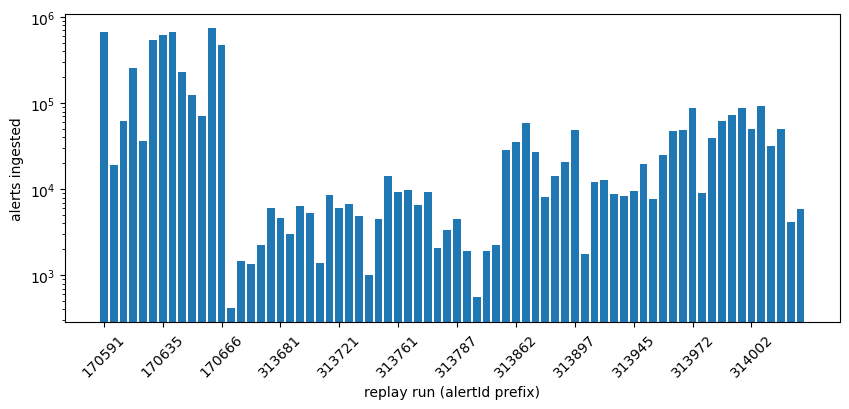

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(rdf)), rdf["alerts"])
ax.set_xticks(range(0, len(rdf), 6), rdf["prefix"][::6], rotation=45)
ax.set_xlabel("replay run (alertId prefix)")
ax.set_ylabel("alerts ingested")
ax.set_yscale("log")
plt.show()

## 3. Catalog properties side by side

From each catalog's `hats.properties`. The working catalog uses leaf directories (`npix_suffix = /`), and
now holds the same number of alerts as the frozen catalog. Its partitions are still the baseline's (plus
new ones for sky the baseline didn't cover), since daily runs never split a pixel.

In [6]:
def props(cat):
    i = cat.catalog_info
    return {
        "catalog_name": i.catalog_name,
        "total_rows": f"{i.total_rows:,}",
        "partitions": len(cat.get_healpix_pixels()),
        "hats_max_rows": f"{i.hats_max_rows:,}",
        "hats_order (deepest)": i.hats_order,
        "moc_sky_fraction": i.moc_sky_fraction,
        "npix_suffix": i.npix_suffix,
        "skymap_order": i.skymap_order,
        "default columns": len(i.default_columns or []),
    }


pd.DataFrame({"working (new)": props(working), "frozen": props(frozen)})

,working (new),frozen
catalog_name,rubin_alert_archive,rubin_alert_archive
total_rows,"16,466,969","16,466,969"
partitions,153,227
hats_max_rows,"2,172,010","198,913"
hats_order (deepest),8,7
moc_sky_fraction,0.31687,0.19786
npix_suffix,/,.parquet
skymap_order,10,10
default columns,25,25


In [7]:
print("Same default columns:", working.catalog_info.default_columns == frozen.catalog_info.default_columns)

# Every file is either the baseline's consolidated Npix=<pixel>.parquet or a logged run's <run_id>.parquet.
files = leaf_files(WORKING)
run_ids = {r.run_id for r in replay_runs}
unexpected = [p for px, fs in files.items() for p in fs if p.name != consolidated_file_name(px) and p.stem not in run_ids]
print("Files not from the baseline or a logged run:", unexpected)
files_per_pixel = pd.Series({px: len(fs) for px, fs in files.items()})
print(f"Files per partition: median {files_per_pixel.median():.0f}, max {files_per_pixel.max()}")

Same default columns: True


Files not from the baseline or a logged run: []
Files per partition: median 24, max 49


## 4. Partitioning

Rows per partition and partitions per HEALPix order. The frozen catalog was cut at ~200k rows from all
16.5M alerts. The working catalog's layout comes from the baseline's 10.8M Jun 26 alerts, and the replay
only added files to it, so partitions over 200k are expected until the catalog is re-imported.

In [8]:
def rows_per_partition(catalog_dir):
    rows = Counter()
    for p in data_files(catalog_dir):
        rows[hats.io.paths.get_healpix_from_path(p)] += pq.read_metadata(p).num_rows
    return pd.Series(rows)


rpp = {"working (new)": rows_per_partition(WORKING), "frozen": rows_per_partition(FROZEN)}
pd.DataFrame({k: v.describe(percentiles=[0.1, 0.5, 0.9]) for k, v in rpp.items()}).round(0).astype(int).T

,count,mean,std,min,10%,50%,90%,max
working (new),153,107627,193046,89,2106,82058,177222,2172010
frozen,227,72542,46115,12,10227,68045,140019,198913


In [9]:
orders = pd.DataFrame(
    {k: Counter(px.order for px in v.index) for k, v in rpp.items()}
).fillna(0).astype(int).sort_index()
orders.index.name = "HEALPix order"
orders.T

HEALPix order,0,1,2,3,4,5,6,7,8
working (new),3,2,2,7,11,10,45,71,2
frozen,0,6,5,27,31,4,30,124,0


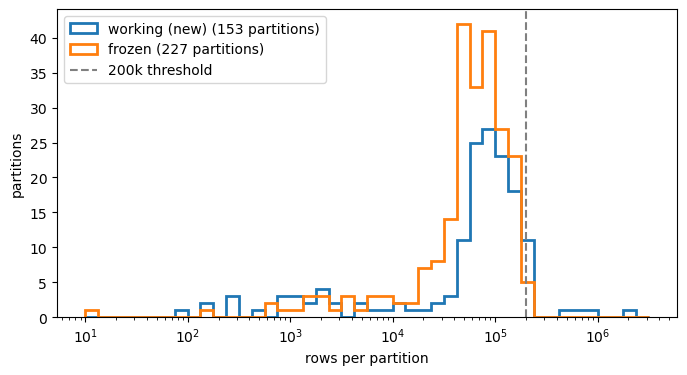

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(1, 6.5, 45)
for name, series in rpp.items():
    ax.hist(series.values, bins=bins, histtype="step", lw=2, label=f"{name} ({len(series)} partitions)")
ax.axvline(200_000, color="gray", ls="--", label="200k threshold")
ax.set_xscale("log")
ax.set_xlabel("rows per partition")
ax.set_ylabel("partitions")
ax.legend()
plt.show()

In [11]:
# Working partitions over the threshold: how many rows came from the baseline vs the replay.
def split_rows(px):
    base = sum(pq.read_metadata(p).num_rows for p in files[px] if p.name == consolidated_file_name(px))
    return {"rows": rpp["working (new)"][px], "from baseline": base, "from replay": rpp["working (new)"][px] - base,
            "files": len(files[px])}


big = rpp["working (new)"][rpp["working (new)"] > 200_000].sort_values(ascending=False)
print(f"{len(big)} working partitions over 200k rows")
pd.DataFrame({str(px): split_rows(px) for px in big.index}).T

6 working partitions over 200k rows


,rows,from baseline,from replay,files
"Order: 0, Pixel: 11",2172010,70950,2101060,12
"Order: 0, Pixel: 4",830403,87813,742590,11
"Order: 0, Pixel: 10",570175,195044,375131,9
"Order: 2, Pixel: 113",432850,62259,370591,7
"Order: 2, Pixel: 138",232407,3416,228991,47
"Order: 6, Pixel: 34329",202965,182046,20919,49


## 5. Columns and schema

Top-level columns, and the number of fields in each nested column. The working catalog is conformed to
alert format 1101 (four new `diaSource` fields, also in `prvDiaSources`), and adds `schemaId`. Every
file the daily runs wrote should have the same schema as the baseline's files.

In [12]:
ws, fs = pq.read_schema(WORKING / "dataset" / "_common_metadata"), pq.read_schema(FROZEN / "dataset" / "_common_metadata")


def n_fields(schema, name):
    t = schema.field(name).type
    return t.num_fields if pa.types.is_struct(t) else "-"


names = list(dict.fromkeys(ws.names + fs.names))
pd.DataFrame(
    {
        "in working": [n in ws.names for n in names],
        "in frozen": [n in fs.names for n in names],
        "fields (working)": [n_fields(ws, n) if n in ws.names else "" for n in names],
        "fields (frozen)": [n_fields(fs, n) if n in fs.names else "" for n in names],
    },
    index=names,
)

,in working,in frozen,fields (working),fields (frozen)
_healpix_29,True,True,-,-
ra,True,True,-,-
dec,True,True,-,-
diaSourceId,True,True,-,-
schemaId,True,False,-,
observation_reason,True,True,-,-
target_name,True,True,-,-
diaSource,True,True,102,98
prvDiaSources,True,True,102,98
prvDiaForcedSources,True,True,14,14


In [13]:
for name in ["diaSource", "prvDiaSources", "prvDiaForcedSources", "diaObject"]:
    w = {f.name for f in ws.field(name).type}
    f = {f.name for f in fs.field(name).type}
    print(f"{name:20s} only in working: {sorted(w - f)}   only in frozen: {sorted(f - w)}")

file_schemas = Counter(pq.read_schema(p).remove_metadata().equals(ws.remove_metadata()) for p in data_files(WORKING))
print(f"\nWorking files with the catalog's schema: {file_schemas[True]} of {sum(file_schemas.values())}")

diaSource            only in working: ['exposureTime', 'reliabilityVersion', 'trailAlgorithm', 'trail_flag']   only in frozen: []
prvDiaSources        only in working: ['exposureTime', 'reliabilityVersion', 'trailAlgorithm', 'trail_flag']   only in frozen: []
prvDiaForcedSources  only in working: []   only in frozen: []
diaObject            only in working: []   only in frozen: []



Working files with the catalog's schema: 3207 of 3207


## 6. Which alerts differ, and when were they observed?

Compare the two catalogs by `diaSourceId` (one alert per row in both). After the replay, they should
hold exactly the same alerts. Then count alerts per observation night (`diaSource.midpointMjdTai`, as
integer MJD) in each catalog; every night should match.

In [14]:
ids = {name: read_column(d, "diaSourceId").to_numpy() for name, d in [("working", WORKING), ("frozen", FROZEN)]}
for name, a in ids.items():
    print(f"{name:8s} rows {len(a):>12,}   unique diaSourceId {len(np.unique(a)):>12,}")

both = np.intersect1d(ids["working"], ids["frozen"])
only_working = np.setdiff1d(ids["working"], ids["frozen"])
only_frozen = np.setdiff1d(ids["frozen"], ids["working"])
pd.Series(
    {"in both": len(both), "only in working (new)": len(only_working), "only in frozen": len(only_frozen)}
).map("{:,}".format).to_frame("alerts")

working  rows   16,466,969   unique diaSourceId   16,466,969


frozen   rows   16,466,969   unique diaSourceId   16,466,969


,alerts
in both,"16,466,969"
only in working (new),0
only in frozen,0


In [15]:
def night_counts(catalog_dir):
    """Alerts per integer MJD."""
    mjd = read_column(catalog_dir, "diaSource.midpointMjdTai").to_numpy()
    return pd.Series(np.floor(mjd).astype(int)).value_counts().sort_index()


nights = pd.DataFrame({"working": night_counts(WORKING), "frozen": night_counts(FROZEN)}).fillna(0).astype(int)
nights.index.name = "MJD"
mismatched = nights[nights["working"] != nights["frozen"]]
print(f"{len(nights)} observation nights, MJD {nights.index.min()} .. {nights.index.max()}; "
      f"{len(mismatched)} with different counts")
mismatched

132 observation nights, MJD 60973 .. 61235; 0 with different counts


,working,frozen
MJD,,


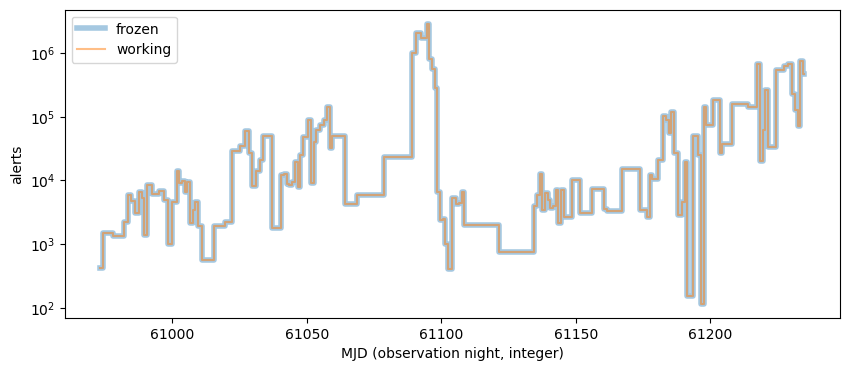

In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
for col, style in [("frozen", dict(lw=4, alpha=0.4)), ("working", dict(lw=1.5, alpha=0.5))]:
    ax.step(nights.index, nights[col], where="mid", label=col, **style)
ax.set_xlabel("MJD (observation night, integer)")
ax.set_ylabel("alerts")
ax.set_yscale("symlog")
ax.legend()
plt.show()

## 7. Spot check: same alert, same values?

For random samples of alerts in both catalogs, compare a few fields: 2,000 alerts the baseline ingested
and 2,000 the replay ingested. Values should be identical (the import only reshapes and adds columns;
it doesn't recompute anything), except `diaObject.diaObjectId` for solar-system alerts (see below).

In [17]:
rng = np.random.default_rng(0)
replay_files = [p for p in data_files(WORKING) if p.stem in run_ids]
replay_ids = read_column(WORKING, "diaSourceId", files=replay_files).to_numpy()
baseline_ids = np.setdiff1d(ids["working"], replay_ids)
samples = {
    "baseline": set(rng.choice(baseline_ids, size=2000, replace=False).tolist()),
    "replay": set(rng.choice(replay_ids, size=2000, replace=False).tolist()),
}
sample = samples["baseline"] | samples["replay"]
fields = [
    "ra", "dec", "diaSource.psfFlux", "diaSource.midpointMjdTai", "diaSource.band",
    "diaSource.diaObjectId", "diaObject.diaObjectId",
]


def sample_values(catalog_dir):
    out = {}
    for f in ["diaSourceId", *fields]:
        out[f] = read_column(catalog_dir, f).to_numpy(zero_copy_only=False)
    df = pd.DataFrame(out)
    return df[df["diaSourceId"].isin(sample)].set_index("diaSourceId")


merged = sample_values(WORKING).join(sample_values(FROZEN), how="inner", lsuffix=" (working)", rsuffix=" (frozen)")
assert len(merged) == len(sample)


def same(f, rows):
    w, fr = merged.loc[rows, f"{f} (working)"], merged.loc[rows, f"{f} (frozen)"]
    return bool(((w == fr) | (w.isna() & fr.isna())).all())


table = {}
for name, s in samples.items():
    rows = merged.index.isin(s)
    col = {f: same(f, rows) for f in fields}
    # Solar-system alerts have no diaObject: frozen stores a placeholder 0, working stores null.
    w, fr = merged.loc[rows, "diaObject.diaObjectId (working)"], merged.loc[rows, "diaObject.diaObjectId (frozen)"]
    null_vs_zero = w.isna() & (fr == 0)
    col["diaObject.diaObjectId (0 = null)"] = bool(((w == fr) | (w.isna() & fr.isna()) | null_vs_zero).all())
    table[f"{name} ({rows.sum()} alerts)"] = col
    print(f"{name}: {null_vs_zero.sum()} sampled alerts are null in working and 0 in frozen (solar-system alerts)")
pd.DataFrame(table)

baseline: 122 sampled alerts are null in working and 0 in frozen (solar-system alerts)
replay: 142 sampled alerts are null in working and 0 in frozen (solar-system alerts)


,baseline (2000 alerts),replay (2000 alerts)
ra,True,True
dec,True,True
diaSource.psfFlux,True,True
diaSource.midpointMjdTai,True,True
diaSource.band,True,True
diaSource.diaObjectId,True,True
diaObject.diaObjectId,False,False
diaObject.diaObjectId (0 = null),True,True


## Takeaways

- **The working catalog now holds exactly the frozen catalog's alerts.** 16,466,969 in each, all unique
  `diaSourceId`s, 0 only in one catalog, and the same count on every one of the 132 observation nights.
- **Every input chunk was ingested exactly once.** 263 baseline + 163 replay chunks, each logged once; input
  footers, catalog files, `ingested.jsonl` and `hats.properties` all agree. Nothing skipped, all format 1100.
- **Interrupted jobs left nothing behind.** Two preempted jobs, and every file in the catalog is either a
  baseline file or a logged run's.
- **Values match** for 2,000 sampled baseline alerts and 2,000 sampled replay alerts, except
  `diaObject.diaObjectId`: frozen has a placeholder 0 for solar-system alerts, working has null (on purpose).
- **Schema:** unchanged from the baseline (the four 1101 fields, plus `schemaId`), and all 3,207 files share it.
- **Partitioning needs a re-import.** Daily runs never split a pixel, so the baseline's sparse layout absorbed
  the replay: 6 partitions are over 200k rows, the largest 2.17M (order 0, pixel 11, 97% from the replay),
  and partitions hold a median of 24 files (up to 49), one per run. The frozen catalog, cut at 200k from
  the same alerts, has 227 partitions with none over 198,913. The planned weekly re-import fixes both.
- **Runs are quick:** median 1.6 min per night (one prefix, a few thousand to 666k alerts) on 8 Dask workers.
- **Not in this catalog yet:** the converter's chunks in `landing/` (171141, 171145, ...), since this replay
  read from the temporary `replay_landing/`.